# Video 2.4 - Solving our problem using DBSCAN

**Problem Statement**: Try out new-age bundled online marketing strategies which would require to group similiar products together irrespective of the segment.

### To perform clustering using DBSCAN you will be following these steps:

1) __Load the Dataset:__ Import the dataset into the Jupyter notebook environment.

2) __Feature Selection:__ Choose the features from the dataset that are relevant for the problem statement.

3) __Pre-process the data:__ Use appropriate pre-processing measures for the problem statement.

4) __Apply DBSCAN Clustering:__ Use the DBSCAN algorithm to cluster the data based on the different number of clusters.

5) __Find Optimal values:__ Find the optimal value for eps using k-plot and set the min_samples

6) __Evaluate and Interpret the Clusters:__ Analyze and interpret the clusters by plotting different features with cluster labels.

### Step1: Load the dataset

In [1]:
import pandas as pd
import numpy as np
import os

os.chdir(r'C:\Users\ongja\Downloads\Intro_ML\Module6')
data_preprocessed = pd.read_csv('Synergix_data_preprocessed_unsupervised_new.csv')
data_preprocessed.head()

,SKU_ID,Date,Page_traffic,Revenue($),Unit_price,Units_sold,Segment,1_Star_Rating,2_Star_Rating,3_Star_Rating,...,Num_of_Promotions,Sum of Spend,Online_Clicks,Online_Cost,Online_Impressions,num_unique_campaigns,Clicks_video,Cost_video,Impressions_video,num_unique_campaigns_offline
0,SKU1011,2021-01-02,4119.0,4650,6.671449,697,Makeup,29.0,21.0,49.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,SKU1011,2021-01-09,4074.0,11435,11.134372,1027,Makeup,36.0,28.0,62.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,SKU1011,2021-01-16,4897.0,11603,11.189007,1037,Makeup,38.0,30.0,64.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,SKU1011,2021-01-23,4783.0,14067,11.880912,1184,Makeup,38.0,30.0,64.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,SKU1011,2021-01-30,3789.0,6188,7.063927,876,Makeup,38.0,30.0,64.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Step2: Feature Selection: Create an aggregated dataset and GroupBy SKU_ID

In [2]:
# Define the aggregation operations
aggregation = {
    
    'Page_traffic':'last',
    'Organic Search Rank': 'last',
    'Image_Count': 'last',
    'Bullet_Count': 'last',
    'Title_Count': 'last',
    'Description_Length': 'last',
    '1_Star_Rating': 'last',
     '2_Star_Rating': 'last',
     '3_Star_Rating': 'last',
     '4_Star_Rating': 'last',
     '5_Star_Rating': 'last',
    'Unit_price':'last',
    'Revenue($)': 'sum',
}

In [3]:
# Group by 'SKU_ID' and aggregate
# data_selected = data_preprocessed.groupby('SKU_ID').agg(aggregation).reset_index()
data_selected = data_preprocessed.groupby('SKU_ID').agg(aggregation)
data_selected

,Page_traffic,Organic Search Rank,Image_Count,Bullet_Count,Title_Count,Description_Length,1_Star_Rating,2_Star_Rating,3_Star_Rating,4_Star_Rating,5_Star_Rating,Unit_price,Revenue($)
SKU_ID,,,,,,,,,,,,,
SKU1011,4995.0,14.0,5.0,5.0,91.0,59.0,75.0,50.0,118.0,237.0,1672.0,18.095471,1805434
SKU1014,87.0,32.0,0.0,5.0,79.0,99.0,89.0,49.0,146.0,257.0,1651.0,20.099526,0
SKU1024,5454.0,30.0,0.0,8.0,163.0,158.0,106.0,66.0,205.0,440.0,2996.0,15.980161,2340227
SKU1025,5356.0,27.0,2.0,6.0,90.0,62.0,152.0,102.0,287.0,604.0,4098.0,19.634593,2432316
SKU1036,3627.0,24.0,12.0,8.0,126.0,221.0,140.0,78.0,228.0,474.0,3479.0,25.186318,2839170
...,...,...,...,...,...,...,...,...,...,...,...,...,...
SKU968,875.0,19.0,9.0,5.0,85.0,56.0,57.0,39.0,116.0,273.0,1803.0,20.905660,0
SKU978,6056.0,30.0,0.0,8.0,167.0,158.0,14.0,9.0,0.0,74.0,533.0,18.176868,2211515
SKU989,583.0,28.0,13.0,6.0,62.0,122.0,162.0,107.0,277.0,571.0,3809.0,20.905660,0


### Step3: Pre-process the data:  Use appropriate pre-processing measures for the problem statement

In [4]:
from sklearn.preprocessing import StandardScaler

# Standardize the numerical columns
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data_selected)

# Create a DataFrame for the scaled data
data_scaled = pd.DataFrame(data_scaled, columns=data_selected.columns, index = data_selected.index)

# Show the first few rows of the scaled DataFrame
data_scaled.head()


,Page_traffic,Organic Search Rank,Image_Count,Bullet_Count,Title_Count,Description_Length,1_Star_Rating,2_Star_Rating,3_Star_Rating,4_Star_Rating,5_Star_Rating,Unit_price,Revenue($)
SKU_ID,,,,,,,,,,,,,
SKU1011,1.100784,-0.411851,-0.411446,-1.576290,-0.551930,-1.284448,-0.209573,-0.229204,-0.389066,-0.409205,-0.320630,-0.627850,-0.062109
SKU1014,-1.351049,1.041026,-1.427309,-1.576290,-0.962336,-0.632472,0.013749,-0.252124,-0.162427,-0.330060,-0.333027,-0.398543,-1.624228
SKU1024,1.330081,0.879595,-1.427309,1.486582,1.910506,0.329194,0.284926,0.137522,0.315134,0.394121,0.460978,-0.869888,0.400611
SKU1025,1.281125,0.637449,-1.020964,-0.555332,-0.586131,-1.235550,1.018701,0.962656,0.978863,1.043114,1.111530,-0.451741,0.480290
SKU1036,0.417388,0.395303,1.010763,1.486582,0.645087,1.356056,0.827281,0.412567,0.501302,0.528668,0.746111,0.183498,0.832313


In [5]:
data_scaled.shape

(239, 13)

### Step4: Apply DBSCAN Clustering

**Finding Optimal *eps* Using Nearest Neighbours**

**Purpose**: Find the right value for eps mathematically, rather than guessing.

In [6]:
from sklearn.neighbors import NearestNeighbors

# Use Nearest Neighbors to find distances to the 26th nearest neighbor
nn = NearestNeighbors(n_neighbors=26).fit(data_scaled)
distances, indices = nn.kneighbors(data_scaled)

**Why n_neighbors=26?**  
- A common rule of thumb: *min_samples = 2 × number of features*. 
- You have 13 features → *min_samples = 26*. 
- So *n_neighbors=26* — you're computing the distance from each product to its 26th nearest neighbor.

In [7]:
import numpy as np

# Sort the distances
distances = np.sort(distances, axis=0)
distances = distances[:, 1]
distances

array([0.27735314, 0.27735314, 0.29801   , 0.29801   , 0.33714824,
       0.33714824, 0.64080237, 0.64080237, 0.71371066, 0.71371066,
       0.76762226, 0.76762226, 0.78542485, 0.78542485, 0.79900172,
       0.79900172, 0.82802726, 0.85101494, 0.85101494, 0.86012208,
       0.89390818, 0.89390818, 0.90613759, 0.90613759, 0.92485945,
       0.92485945, 0.94110044, 0.94110044, 0.98698488, 0.98698488,
       1.02165203, 1.02165203, 1.0230166 , 1.0230166 , 1.05900314,
       1.06665013, 1.06665013, 1.07304164, 1.07304164, 1.08962782,
       1.11405589, 1.11542327, 1.11542327, 1.13905464, 1.13905464,
       1.14054027, 1.14054027, 1.14989996, 1.14989996, 1.16273614,
       1.17232834, 1.17232834, 1.1742597 , 1.1742597 , 1.17476596,
       1.17534739, 1.18451   , 1.19498238, 1.19498238, 1.19853134,
       1.19853134, 1.20521418, 1.20521418, 1.20761378, 1.22001888,
       1.22001888, 1.25808368, 1.26767355, 1.27121413, 1.27121413,
       1.29580501, 1.3079239 , 1.32023134, 1.32347828, 1.32420

## Step5: Find Optimal values for min_samples and eps

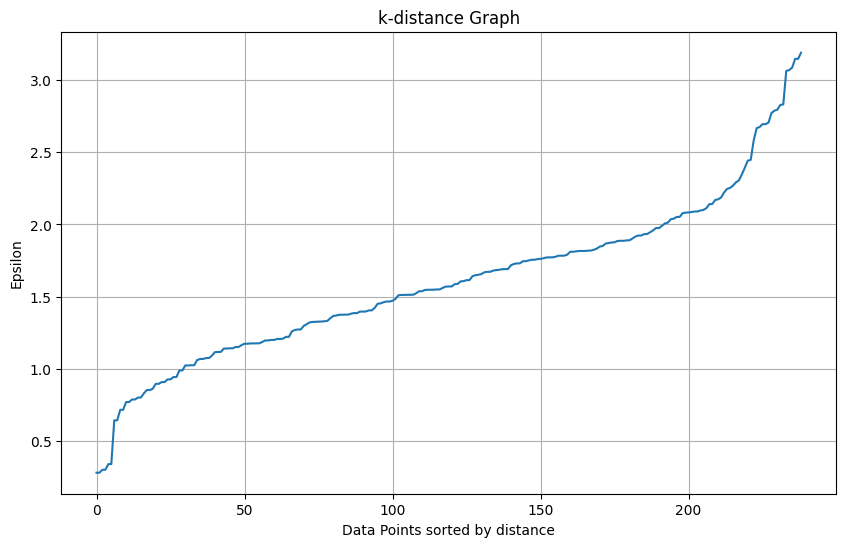

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.plot(distances)
plt.title("k-distance Graph")
plt.xlabel("Data Points sorted by distance")
plt.ylabel("Epsilon")
plt.grid(True)
plt.show()

#### Running DBSCAN

In [9]:
from sklearn.cluster import DBSCAN

# Apply DBSCAN clustering
dbscan = DBSCAN(eps=3, min_samples=26)
data_scaled['DBSCAN_cluster'] = dbscan.fit_predict(data_scaled)
data_scaled

,Page_traffic,Organic Search Rank,Image_Count,Bullet_Count,Title_Count,Description_Length,1_Star_Rating,2_Star_Rating,3_Star_Rating,4_Star_Rating,5_Star_Rating,Unit_price,Revenue($),DBSCAN_cluster
SKU_ID,,,,,,,,,,,,,,
SKU1011,1.100784,-0.411851,-0.411446,-1.576290,-0.551930,-1.284448,-0.209573,-0.229204,-0.389066,-0.409205,-0.320630,-0.627850,-0.062109,0
SKU1014,-1.351049,1.041026,-1.427309,-1.576290,-0.962336,-0.632472,0.013749,-0.252124,-0.162427,-0.330060,-0.333027,-0.398543,-1.624228,0
SKU1024,1.330081,0.879595,-1.427309,1.486582,1.910506,0.329194,0.284926,0.137522,0.315134,0.394121,0.460978,-0.869888,0.400611,0
SKU1025,1.281125,0.637449,-1.020964,-0.555332,-0.586131,-1.235550,1.018701,0.962656,0.978863,1.043114,1.111530,-0.451741,0.480290,0
SKU1036,0.417388,0.395303,1.010763,1.486582,0.645087,1.356056,0.827281,0.412567,0.501302,0.528668,0.746111,0.183498,0.832313,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SKU968,-0.957397,-0.008274,0.401245,-1.576290,-0.757133,-1.333346,-0.496702,-0.481328,-0.405255,-0.266743,-0.243296,-0.306303,-1.624228,0
SKU978,1.630816,0.879595,-1.427309,1.486582,2.047308,0.329194,-1.182622,-1.168940,-1.344188,-1.054241,-0.993025,-0.618537,0.289246,-1
SKU989,-1.103268,0.718164,1.213936,-0.555332,-1.543745,-0.257585,1.178217,1.077258,0.897921,0.912524,0.940923,-0.306303,-1.624228,-1


#### Checking Cluster Counts and Noise

In [10]:
# Check the number of clusters and noise points
cluster_counts = data_scaled['DBSCAN_cluster'].value_counts()

cluster_counts

DBSCAN_cluster
 0    211
-1     28
Name: count, dtype: int64

Observation:
```python
Cluster  0:  211 products   (88%)
Noise   -1:   28 products   (12%)
Total:        239 products
```
>DBSCAN found **only 1 cluster + 28 noise points**